<a href="https://colab.research.google.com/github/tevfikaytekin/recommender_systems_course/blob/main/ranking_evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Ranking Evaluation

The measures below can be used to measure the goodness of a ranked list. This is particularly important for evaluating recommender systems, where we need to assess how well our suggested items (movies, products, articles, etc.) match a user's preferences.

In [ ]:
import scipy.stats as stats
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn import linear_model
from sklearn.metrics import mean_squared_error, mean_absolute_error

Suppose that we have a set of items some of which are relevant. For example:

items: a, b, c, d, e, f, g <br>
rel_items = b, f

You can think of these items as movies. The relevant items are those which a user U watched (or liked) in the past. We want to rank these items according to their relevance to user U.

Suppose that we use two different methods: A and B.

The best ranking is the one which puts the relevant items at the top two positions but there are many other possibilties. For example the following shows two possible rankings produced by these methods (A leftward position signifies a higher ranking):

A = [c, b, a, f, g, e, d] <br>
B = [b, a, g, c, g, f, e]

Which ranking is better, given that b and f are the relevant items?

To answer this question we need measures for evaluating the goodness of a ranking.


### hits@k

Measures the number of relevant items at top k positions.

**Formula:**
$$ \text{hits@k} = \sum_{i=1}^{k} \mathbf{1}(\text{item}_i \in \text{relevant_items}) $$

* **When to use:** When you care about the raw count of relevant items presented to the user in a fixed-size window, regardless of the total number of relevant items that exist.
* **Scenario:** An e-commerce "Recommended for You" carousel showing exactly 5 items. You want to measure exactly how many of those 5 items the user actually clicked or bought.

In [3]:
def hits_at(ranked_items, rel_items, k):
    hits = 0
    n = min(k, len(ranked_items))
    for i in range(n):
        if (ranked_items[i] in rel_items):
            hits += 1
    return hits

In [2]:
ranked_items = ["b","a","c","d","e"]
rel_items = ["b","e"]

In [5]:
hits_at(ranked_items, rel_items, 5)

2

### precision@k

Measures the proportion of relevant items at top k positions.

**Formula:**
$$ \text{precision@k} = \frac{\text{hits@k}}{k} = \frac{1}{k} \sum_{i=1}^{k} \mathbf{1}(\text{item}_i \in \text{relevant_items}) $$

* **When to use:** When the "purity" of the top-k results is critical. You want to ensure that most of what the user sees immediately is highly relevant (avoiding false positives).
* **Scenario:** A "Top 10 Songs You Might Like" playlist generated for a user. Users typically only listen to the first few tracks, so a high percentage of those top recommendations must match their music taste.

In [6]:
def precision_at(ranked_items, rel_items, k):
    hits = hits_at(ranked_items, rel_items, k)
    return hits/k

In [13]:
ranked_items = ["a","b","c","d","e"]
rel_items = ["b","a","c"]

In [14]:
precision_at(ranked_items, rel_items,5)

0.6

### Hit Ratio @ k

Measures whether there is at least one relevant item in the top `k` positions. It returns 1 if true, and 0 otherwise.

**Formula:**
$$ \text{Hit Ratio@k} = \mathbf{1}(\text{hits@k} > 0) $$

* **When to use:** When a single relevant recommendation is considered a complete success. It doesn't matter if you show 1 relevant item or 5; the user only needs one.
* **Scenario:** Suggesting a replacement charging cable for a specific phone. The user only needs to buy one cable, so as long as at least one compatible cable is in the top `k` recommendations, it's a win.

In [19]:
def hit_ratio_at(ranked_items, rel_items, k):
    if hits_at(ranked_items, rel_items, k) > 0:
        return 1
    else:
        return 0

In [20]:
ranked_items = ["a","b","c","d","e"]
rel_items = ["b","e"]

print(f"Hit ratio @ 3 for ranked_items: {hit_ratio_at(ranked_items, rel_items, 3)}")
print(f"Hit ratio @ 1 for ranked_items: {hit_ratio_at(ranked_items, rel_items, 1)}")

ranked_items_no_hit = ["a","c","d","f","g"]
print(f"Hit ratio @ 3 for ranked_items_no_hit: {hit_ratio_at(ranked_items_no_hit, rel_items, 3)}")

Hit ratio @ 3 for ranked_items: 1
Hit ratio @ 1 for ranked_items: 0
Hit ratio @ 3 for ranked_items_no_hit: 0


### recall@k

Measures the proportion of relevant items at top-k relative to all relevant items

**Formula:**
$$ \text{recall@k} = \frac{\text{hits@k}}{|\text{relevant_items}|} = \frac{\sum_{i=1}^{k} \mathbf{1}(\text{item}_i \in \text{relevant_items})}{|\text{relevant_items}|} $$

* **When to use:** When failing to find relevant items is highly penalized (avoiding false negatives). You want to surface as many of the total existing relevant items as possible in the top `k`.
* **Scenario:** Recommending niche content, like suggesting documentaries about a specific historical event a user is intensely researching. If they want comprehensive coverage, missing a key documentary is a failure, so maximizing recall is the primary goal.

In [15]:
def recall_at(ranked_items, true_items, k):
    if not true_items:
        return 0.0
    hits = hits_at(ranked_items, true_items, k)
    return hits/len(true_items)


In [17]:
ranked_items = ["a","b","c","d","e"]
rel_items = ["b","e"]

In [18]:
recall_at(ranked_items, rel_items,3)

0.5

Depending on the applications you can choose the size of k. For example, in a typical web application where 5 items are recommended to the user k=5 might be a good choice. On the other hand, in a mobile web applcation where only 1 item can be shown to the user you might choose k = 1.

A problem of these measures is that they do not consider the order of the relevant items at top k positions. For example, for the following scenario:

items: a, b, c, d, e, f, g <br>
rel_items = b, f

Given the following rankings:

A = [c, b, f, a, g, e, d] <br>
B = [b, f, g, c, g, a, e]

hits@3 (hence precisipn@3 and recall@3) will be the same for both rankings, however, B is better than A. To account for this, more complicated metrics formulated.


### Reciprocal Rank

**Formula:**
$$ \text{RR} = \frac{1}{\text{rank}_{first\_relevant}} $$
*(Note: Mean Reciprocal Rank (MRR) is simply the average of RR across multiple queries/users).*

* **When to use:** For "known-item" or sequential recommendations where there is usually only *one* highly desired answer, and you care about its absolute rank.
* **Scenario:** "Next-in-sequence" recommendations, such as suggesting exactly the next episode of a TV show a user is binge-watching. You want the very next episode to be exactly at rank 1.

In [21]:
# See http://en.wikipedia.org/wiki/Mean_reciprocal_rank
def reciprocal_rank(ranked_items, rel_items):
    pos = 0
    for item in ranked_items:
        if item in rel_items:
            return 1 / (pos+1)
        pos += 1
    return 0


In [ ]:
ranked_items1 = ["c", "b", "f", "a", "g", "e", "d"]
ranked_items2 = ["b", "f", "g", "c", "g", "a", "e"]
rel_items = ["b","f"]

In [ ]:
print("ranking 1: ",reciprocal_rank(ranked_items1, rel_items))
print("ranking 2: ",reciprocal_rank(ranked_items2, rel_items))

ranking 1:  0.5
ranking 2:  1.0


### Normalized Discounted Cumulative Gain (NDCG)

For **binary relevance**, the standard Discounted Cumulative Gain (DCG) formula is:
$$ \text{DCG}_k = \sum_{i=1}^{k} \frac{\mathbf{1}(\text{item}_i \in \text{relevant_items})}{\log_2(i + 1)} $$

**Normalized DCG (NDCG)** scales this by the Ideal DCG (the maximum possible DCG if the items were perfectly sorted):
$$ \text{NDCG}_k = \frac{\text{DCG}_k}{\text{IDCG}_k} $$

* **When to use:** When relevance isn't just binary (yes/no) but comes in grades (e.g., highly relevant, somewhat relevant, irrelevant) AND when rank position strongly dictates user attention. It heavily discounts the value of items placed lower down.
* **Scenario:** Movie recommendations. Instead of just "liked" or "didn't like", you have 5-star ratings (graded relevance). You want to ensure that the 5-star movies appear at the top and 4-star movies next, heavily penalizing the system if a 2-star movie ends up taking the #1 spot.

In [27]:
# Computes the ideal DCG given the number of positive items
def compute_IDCG(n):
    idcg = 0
    for i in range(n):
        idcg += 1 / np.log2(i+2)
    return idcg

In [28]:
def NDCG(ranked_items, rel_items):
    if not rel_items:
        return 0.0
    dcg = 0
    idcg = compute_IDCG(len(rel_items))
    for i in range(len(ranked_items)):
        if ranked_items[i] in rel_items:
            dg = 1 / np.log2(i+2)
            dcg += dg
            #print(dg)
    return dcg/idcg


In [29]:
ranked_items1 = ["a", "b", "c", "f", "g", "e", "d"]
ranked_items2 = ["d", "c", "f", "g", "a", "e", "b"]
rel_items = ["b","f"]


In [30]:
import numpy as np
print("ranking 1: ",NDCG(ranked_items1, rel_items))
print("ranking 2: ",NDCG(ranked_items2, rel_items))

ranking 1:  0.6509209298071326
ranking 2:  0.5109559939712153


### NDCG Decay

NDCG scales by $1/\log_2(rank+1)$, which drops smoothly as the rank increases.

Let's plot the score for a scenario where we have exactly one relevant item (`"a"`), and we keep pushing it further down the ranked list. Notice how NDCG decays!

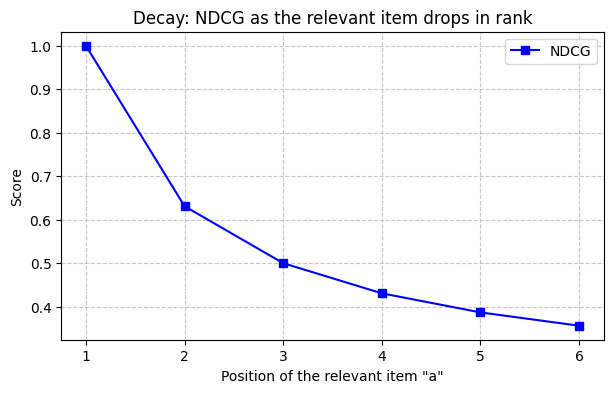

In [ ]:
rel_items = ["a"]
rankings = [
    ["a", "b", "c", "d", "e", "f"], # Rank 1
    ["b", "a", "c", "d", "e", "f"], # Rank 2
    ["b", "c", "a", "d", "e", "f"], # Rank 3
    ["b", "c", "d", "a", "e", "f"], # Rank 4
    ["b", "c", "d", "e", "a", "f"], # Rank 5
    ["b", "c", "d", "e", "f", "a"]  # Rank 6
]

ndcg_scores = []

for rank in rankings:
    ndcg_scores.append(NDCG(rank, rel_items))

# Plotting the difference
plt.figure(figsize=(7, 4))
plt.plot(range(1, 7), ndcg_scores, label='NDCG', marker='s', color='blue')
plt.title('Decay: NDCG as the relevant item drops in rank')
plt.xlabel('Position of the relevant item "a"')
plt.ylabel('Score')
plt.xticks(range(1, 7))
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()
plt.show()

### Graded NDCG

The `NDCG` function we defined earlier assumed **binary relevance** (the numerator was simply `1` if the item was relevant, and `0` otherwise).

When we have **graded relevance** (e.g., ratings from 0 to 5, where 5 is highly relevant), the standard DCG formula incorporates the grade into the numerator:

$$ DCG = \sum_{i=1}^{p} \frac{2^{rel_i} - 1}{\log_2(i + 1)} $$

* **Numerator ($2^{rel_i} - 1$):** Heavily rewards items with high relevance scores. A 5-star item will add a much larger value than a 1-star item.
* **Denominator ($\log_2(i + 1)$):** Penalizes items that are ranked lower down the list.

Let's implement a version of NDCG that accepts a list of relevance scores (grades) instead of a list of binary matches.

In [ ]:
def graded_DCG(ranked_scores):
    """Calculates DCG for a ranked list of relevance scores."""
    dcg = 0
    for i, score in enumerate(ranked_scores):
        # rank i is 0-indexed, so we use i+2 for the log base 2
        dcg += (2**score - 1) / np.log2(i + 2)
    return dcg

def graded_NDCG(ranked_scores):
    """Calculates Normalized DCG for a ranked list of relevance scores."""
    if not ranked_scores:
        return 0.0

    # Calculate actual DCG
    dcg = graded_DCG(ranked_scores)

    # Calculate Ideal DCG by sorting the scores in descending order
    ideal_scores = sorted(ranked_scores, reverse=True)
    idcg = graded_DCG(ideal_scores)

    # Handle edge case where max possible score is 0
    if idcg == 0:
        return 0.0

    return dcg / idcg

# Example Scenario:
# 3 = Highly relevant, 2 = Relevant, 1 = Slightly relevant, 0 = Irrelevant

# System A puts the highly relevant items first
ranking_A_scores = [3, 2, 1, 0, 0]

# System B puts a slightly relevant item first, pushing the highly relevant one down
ranking_B_scores = [1, 0, 2, 3, 0]

print(f"Graded NDCG for Ranking A (Optimal): {graded_NDCG(ranking_A_scores):.4f}")
print(f"Graded NDCG for Ranking B (Suboptimal): {graded_NDCG(ranking_B_scores):.4f}")

Graded NDCG for Ranking A (Optimal): 1.0000
Graded NDCG for Ranking B (Suboptimal): 0.5871


## Exercises

Test your understanding of the ranking metrics with these practice questions!

**Exercise 1: Precision and Recall**
Suppose a movie recommendation system returns the following ranked items: `["movie3", "movie1", "movie4", "movie2", "movie5"]`.
The user actually watched and liked `["movie1", "movie2"]`.
Calculate `precision@3` and `recall@3`.

**Exercise 2: Reciprocal Rank**
For a next-episode recommender, System A returns `["ep3", "ep4", "ep5"]` and the correct next episode the user wants is `"ep5"`.
System B returns `["ep5", "ep6", "ep3"]` for the same user.
What is the Reciprocal Rank for System A and System B?

**Exercise 3: Hit Ratio**
A recommendation system suggests 2 items: `["item_X", "item_Y"]`. The user's actual favorite items are `["item_A", "item_B", "item_Y"]`.
What is the `Hit Ratio@2`?

**Exercise 4: Graded DCG**
Calculate the Graded DCG (not normalized) for a list of 3 recommended products with assigned user ratings `[2, 0, 1]`.
*(Hint: use the formula $DCG = \sum \frac{2^{rel_i} - 1}{\log_2(i + 1)}$ where $i$ is the 1-based rank).*

## Solutions

**Solution 1: Precision and Recall**
*   **Top 3 items are:** `["movie3", "movie1", "movie4"]`.
*   **Relevant items in Top 3:** Only `"movie1"` (so `hits@3 = 1`).
*   `precision@3` = $1 / 3 \approx \mathbf{0.333}$
*   `recall@3` = $1 / 2 = \mathbf{0.5}$ (since there are 2 total relevant movies in existence).

**Solution 2: Reciprocal Rank**
*   **System A:** "ep5" is at rank 3. $\text{RR} = \frac{1}{3} \approx \mathbf{0.333}$
*   **System B:** "ep5" is at rank 1. $\text{RR} = \frac{1}{1} = \mathbf{1.0}$

**Solution 3: Hit Ratio**
*   The top 2 items are `["item_X", "item_Y"]`.
*   "item_Y" is in the relevant list `["item_A", "item_B", "item_Y"]`.
*   Because there is at least 1 hit in the top 2, `Hit Ratio@2` = **1**

**Solution 4: Graded DCG**
*   **Rank 1** (score = 2): $\frac{2^2 - 1}{\log_2(1+1)} = \frac{3}{1} = 3$
*   **Rank 2** (score = 0): $\frac{2^0 - 1}{\log_2(2+1)} = \frac{0}{1.585} = 0$
*   **Rank 3** (score = 1): $\frac{2^1 - 1}{\log_2(3+1)} = \frac{1}{2} = 0.5$
*   **Total Graded DCG** = $3 + 0 + 0.5 = \mathbf{3.5}$

In [ ]:
# Let's verify our manual calculations using the functions we defined!

# Solution 1
ranked_docs = ["movie3", "movie1", "movie4", "movie2", "movie5"]
rel_docs = ["movie1", "movie2"]
print(f"Ex 1 - Precision@3: {precision_at(ranked_docs, rel_docs, 3):.3f}")
print(f"Ex 1 - Recall@3: {recall_at(ranked_docs, rel_docs, 3):.3f}")

# Solution 2
sys_A = ["ep3", "ep4", "ep5"]
sys_B = ["ep5", "ep6", "ep3"]
target = ["ep5"]
print(f"\nEx 2 - RR System A: {reciprocal_rank(sys_A, target):.3f}")
print(f"Ex 2 - RR System B: {reciprocal_rank(sys_B, target):.3f}")

# Solution 3
recs = ["item_X", "item_Y"]
favs = ["item_A", "item_B", "item_Y"]
print(f"\nEx 3 - Hit Ratio@2: {hit_ratio_at(recs, favs, 2)}")

# Solution 4
scores = [2, 0, 1]
print(f"\nEx 4 - Graded DCG: {graded_DCG(scores):.3f}")

Ex 1 - Precision@3: 0.333
Ex 1 - Recall@3: 0.500

Ex 2 - RR System A: 0.333
Ex 2 - RR System B: 1.000

Ex 3 - Hit Ratio@2: 1

Ex 4 - Graded DCG: 3.500
